<div dir="rtl">

# طبقه‌بندی ارقام MNIST با استفاده از پرسپترون چندلایه (MLP)

این بخش به پیاده‌سازی، آموزش و ارزیابی مقایسه‌ای شبکه‌های عصبی تمام‌متصل (MLP) روی مجموعه داده **MNIST** اختصاص دارد. هدف اصلی، تحلیل رفتار توابع فعال‌ساز مختلف (`ReLU` و `ELU`)، الگوریتم‌های بهینه‌سازی (`Adam`، `AdamW`، `SGD + Momentum`) و بررسی سقف عملکردی مدل‌های مسطح (Flat) پیش از ورود به شبکه‌های کانولوشنی (CNN) است.

---

## ۱. مشخصات مجموعه داده (Dataset Overview)

* **ابعاد ورودی:** تصاویر تک‌کاناله (Grayscale) با ابعاد $28 \times 28$ پیکسل (مسطح‌شده به بردار ۷۸۴تایی).
* **کلاس‌های خروجی:** ۱۰ کلاس (ارقام ۰ تا ۹).
* **تابع هزینه:** `nn.CrossEntropyLoss()` (نیازمند لیبل‌های نوع `torch.long`).
* **اندازه بچ (Batch Size):** ۲۵۶
* **تعداد اپوک (Epochs):** ۵۰

---

## ۲. مشخصات و پیکربندی معماری مدل‌ها

| مشخصه | مدل ۱ (Model 1) | مدل ۲ (Model 2) | مدل ۳ (Model 3) |
| :--- | :--- | :--- | :--- |
| **تعداد پارامترهای آموزش‌پذیر** | **121,450** | **115,306** | **111,146** |
| **لایه‌ها** | $784 \to 128 \to 128 \to 32 \to 10$ | $784 \to 128 \to 64 \to 64 \to 32 \to 10$ | $784 \to 128 \to 64 \to 32 \to 10$ |
| **تابع فعال‌ساز** | `ReLU` | `ELU` | `ELU` |
| **بهینه‌ساز** | `Adam` | `AdamW` | `SGD` (Momentum = 0.9) |
| **نرخ یادگیری ($lr$)** | $0.001$ | $0.001$ | $0.001$ |
| **Weight Decay** | $0.001$ | $0.001$ | $0.001$ |

---

## ۳. نتایج ارزیابی نهایی (Test Evaluation)

| مدل | تعداد پارامتر | تابع فعال‌ساز | بهینه‌ساز | دقت داده تست (Test Accuracy) |
| :--- | :---: | :--- | :--- | :---: |
| **Model 1** | 121,450 | ReLU | Adam | **97.61%** |
| **Model 2** | 115,306 | ELU | AdamW | **98.19%** |
| **Model 3** | 111,146 | ELU | SGD (Momentum) | **97.19%** |

---

## ۴. تحلیل نتایج و گام بعدی

1. **برتری ترکیب ELU و AdamW:** مدل ۲ علی‌رغم داشتن حدود ۶,۱۰۰ پارامتر کمتر نسبت به مدل ۱، با تفکیک تدریجی ابعاد لایه‌ها و بهره‌گیری از بهینه‌ساز `AdamW` به بالاترین دقت (**۹۸.۱۹٪**) دست یافت.
2. **محدودیت ذاتی MLP در بینایی ماشین:** به دلیل مسطح‌سازی ماتریس تصویر ($28 \times 28 \to 784$)، اطلاعات مجاورت فضایی پیکسل‌ها (Spatial Locality) از بین رفته و دقت مدل حول بازه ۹۸٪ متوقف می‌شود.
3. **انتقال به فاز بعد:** برای دستیابی به دقت‌های بالای ۹۹٪ و عدم حساسیت به جابه‌جایی مکانی ارقام (Translation Invariance)، معماری‌های مبتنی بر کانوولوشن (از جمله **LeNet-5**) در مخزن اختصاصی `vision-architectures-pytorch` پیاده‌سازی خواهند شد.

</div>

# 01. Digit Recognition on MNIST using MLP
- Task: Multiclass Classification (10 Classes)
- Framework: PyTorch

## 1. Imports & Setup

In [142]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cffi import model
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset , DataLoader

In [143]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 2. Load Data & Exploratory Data Analysis (EDA)

In [144]:
df_train = pd.read_csv("../data/mnist_train.csv")
df_test = pd.read_csv("../data/mnist_test.csv")

In [145]:
print("size of train: ", (df_train.shape[0]))
print("size of test: ", len(df_test))

size of train:  60000
size of test:  10000


In [146]:
print("df train nan: ", df_train.isna().sum().sum())
print("df test nan: ", df_test.isna().sum().sum())

df train nan:  0
df test nan:  0


## 3. Data Visualization


label = 0


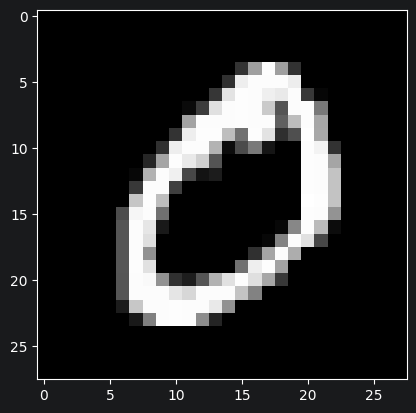

In [147]:
plt.imshow(df_train.iloc[1,1:].values.reshape(28,28),cmap='gray')
print(f"label = {df_train.loc[1].values[0]}")

## 4. Preprocessing & DataLoaders

In [148]:
df_train_x = df_train.iloc[1:,1:].values
df_train_y = df_train.iloc[1:,0].values
X_test = df_test.iloc[1:,1:].values
y_test = df_test.iloc[1:,0].values

In [149]:
X_train , X_val , y_train , y_val = train_test_split(df_train_x, df_train_y, test_size=0.2, random_state=42)

In [150]:
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"df_test_x shape: {X_test.shape}, df_test_y shape: {y_test.shape}")

X_train shape: (47999, 784), y_train shape: (47999,)
X_val shape: (12000, 784), y_val shape: (12000,)
df_test_x shape: (9999, 784), df_test_y shape: (9999,)


In [151]:
X_train = torch.tensor(X_train,dtype=torch.float32)
X_val = torch.tensor(X_val,dtype=torch.float32)
y_train = torch.tensor(y_train,dtype=torch.int64)
y_val = torch.tensor(y_val,dtype=torch.int64)
X_test = torch.tensor(X_test,dtype=torch.float32)
y_test = torch.tensor(y_test,dtype=torch.int64)

In [152]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

In [153]:
train_loader = DataLoader(train_dataset , batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset , batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset , batch_size=256, shuffle=False)

## 5. Model Architecture


In [154]:
model_1 = nn.Sequential(
    nn.Linear(28*28, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, 10)
)

model_2 = nn.Sequential(
    nn.Linear(28*28, 128),
    nn.ELU(),
    nn.Linear(128, 64),
    nn.ELU(),
    nn.Linear(64, 64),
    nn.ELU(),
    nn.Linear(64, 32),
    nn.ELU(),
    nn.Linear(32, 10)
)

model_3 = nn.Sequential(
    nn.Linear(28*28, 128),
    nn.ELU(),
    nn.Linear(128, 64),
    nn.ELU(),
    nn.Linear(64, 32),
    nn.ELU(),
    nn.Linear(32, 10)
)

In [155]:
list_model = [model_1, model_2, model_3]

for idx, model in enumerate(list_model, start=1):
    total_parameters = 0
    for  p in model.parameters():
        if p.requires_grad:
            total_parameters += p.numel()

    print(f"model {idx} has {total_parameters} trainable parameters")

model 1 has 121450 trainable parameters
model 2 has 115306 trainable parameters
model 3 has 111146 trainable parameters


## 6. Loss Function & Optimizer

In [156]:
criterion = nn.CrossEntropyLoss()

In [161]:
optimizer_1 = torch.optim.Adam(model_1.parameters(), lr=0.001 , weight_decay=0.001)
optimizer_2 = torch.optim.AdamW(model_2.parameters(), lr=0.001 , weight_decay=0.001)
optimizer_3 = torch.optim.SGD(model_3.parameters(), lr=0.001 , momentum=0.9,weight_decay=0.001)

## 7. Training & Evaluation Pipeline

In [164]:
def train_model(model,device, train_loader, optimizer, num_of_epoch,model_name,print_every=10):
    train_loss = []
    val_loss = []
    current_loss = float('inf')
    model.to(device)
    for epoch in range(num_of_epoch):
        model.train()

        total_train_loss = 0

        for x_batch ,y_batch in train_loader:
            x_batch , y_batch = x_batch.to(device), y_batch.to(device)

            #zero_grad
            optimizer.zero_grad()

            #forward
            output = model(x_batch)
            loss = criterion(output, y_batch)
            total_train_loss += loss.item() * x_batch.size(0)

            #backward
            loss.backward()
            optimizer.step()

        avg_train_loss = total_train_loss / len(train_loader.dataset)
        train_loss.append(avg_train_loss)

        with torch.no_grad():
            model.eval()
            total_val_loss = 0
            for x_batch, y_batch in val_loader:
                x_batch , y_batch = x_batch.to(device), y_batch.to(device)
                output = model(x_batch)
                loss = criterion(output, y_batch)
                total_val_loss += loss.item() * x_batch.size(0)

            avg_val_loss = total_val_loss /len(val_loader.dataset)
            val_loss.append(avg_val_loss)

        if epoch % print_every == 9:
            print(f"{model_name} : Epoch {epoch+1}/{num_of_epoch} , train_loss: {avg_train_loss:.4f} , val_loss: {avg_val_loss:.4f}")
        if current_loss > avg_val_loss:
            print(f"{epoch+1} : <<<model has improved,saving model>>>>>")
            torch.save(model.state_dict(), f"mnist_mlp_model_{model_name}.pth")

    plt.figure(figsize = (10,10))
    plt.plot(train_loss,label="train_loss")
    plt.plot(val_loss,label="val_loss")
    plt.show()


1 : <<<model has improved,saving model>>>>>
2 : <<<model has improved,saving model>>>>>
3 : <<<model has improved,saving model>>>>>
4 : <<<model has improved,saving model>>>>>
5 : <<<model has improved,saving model>>>>>
6 : <<<model has improved,saving model>>>>>
7 : <<<model has improved,saving model>>>>>
8 : <<<model has improved,saving model>>>>>
9 : <<<model has improved,saving model>>>>>
model_1 : Epoch 10/50 , train_loss: 0.0231 , val_loss: 0.1321
10 : <<<model has improved,saving model>>>>>
11 : <<<model has improved,saving model>>>>>
12 : <<<model has improved,saving model>>>>>
13 : <<<model has improved,saving model>>>>>
14 : <<<model has improved,saving model>>>>>
15 : <<<model has improved,saving model>>>>>
16 : <<<model has improved,saving model>>>>>
17 : <<<model has improved,saving model>>>>>
18 : <<<model has improved,saving model>>>>>
19 : <<<model has improved,saving model>>>>>
model_1 : Epoch 20/50 , train_loss: 0.0224 , val_loss: 0.1234
20 : <<<model has improved,sav

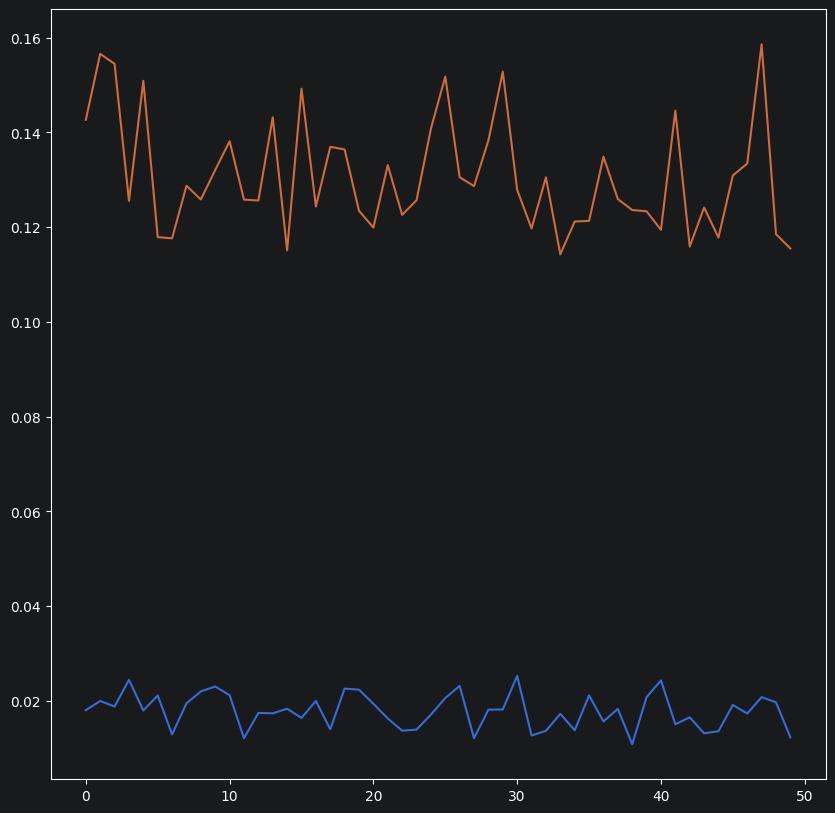

In [165]:
train_model(model_1,device,train_loader,optimizer_1,50,"model_1")

1 : <<<model has improved,saving model>>>>>
2 : <<<model has improved,saving model>>>>>
3 : <<<model has improved,saving model>>>>>
4 : <<<model has improved,saving model>>>>>
5 : <<<model has improved,saving model>>>>>
6 : <<<model has improved,saving model>>>>>
7 : <<<model has improved,saving model>>>>>
8 : <<<model has improved,saving model>>>>>
9 : <<<model has improved,saving model>>>>>
model_2 : Epoch 10/50 , train_loss: 0.0079 , val_loss: 0.1851
10 : <<<model has improved,saving model>>>>>
11 : <<<model has improved,saving model>>>>>
12 : <<<model has improved,saving model>>>>>
13 : <<<model has improved,saving model>>>>>
14 : <<<model has improved,saving model>>>>>
15 : <<<model has improved,saving model>>>>>
16 : <<<model has improved,saving model>>>>>
17 : <<<model has improved,saving model>>>>>
18 : <<<model has improved,saving model>>>>>
19 : <<<model has improved,saving model>>>>>
model_2 : Epoch 20/50 , train_loss: 0.0000 , val_loss: 0.1778
20 : <<<model has improved,sav

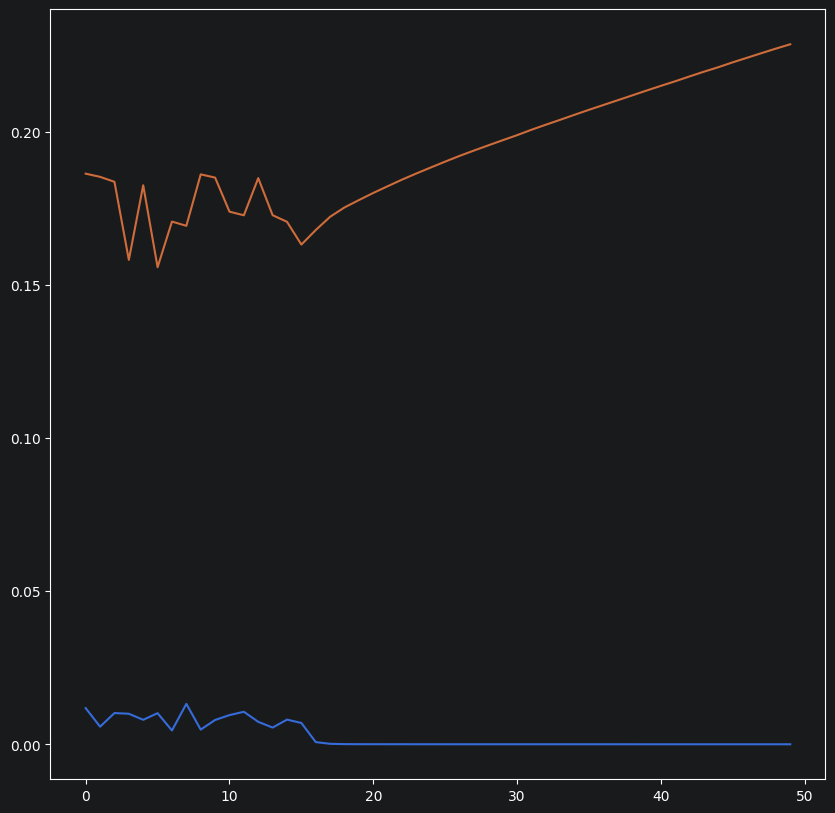

In [166]:
train_model(model_2,device,train_loader,optimizer_2,50,"model_2")

1 : <<<model has improved,saving model>>>>>
2 : <<<model has improved,saving model>>>>>
3 : <<<model has improved,saving model>>>>>
4 : <<<model has improved,saving model>>>>>
5 : <<<model has improved,saving model>>>>>
6 : <<<model has improved,saving model>>>>>
7 : <<<model has improved,saving model>>>>>
8 : <<<model has improved,saving model>>>>>
9 : <<<model has improved,saving model>>>>>
model_3 : Epoch 10/50 , train_loss: 0.0594 , val_loss: 0.1323
10 : <<<model has improved,saving model>>>>>
11 : <<<model has improved,saving model>>>>>
12 : <<<model has improved,saving model>>>>>
13 : <<<model has improved,saving model>>>>>
14 : <<<model has improved,saving model>>>>>
15 : <<<model has improved,saving model>>>>>
16 : <<<model has improved,saving model>>>>>
17 : <<<model has improved,saving model>>>>>
18 : <<<model has improved,saving model>>>>>
19 : <<<model has improved,saving model>>>>>
model_3 : Epoch 20/50 , train_loss: 0.0191 , val_loss: 0.1222
20 : <<<model has improved,sav

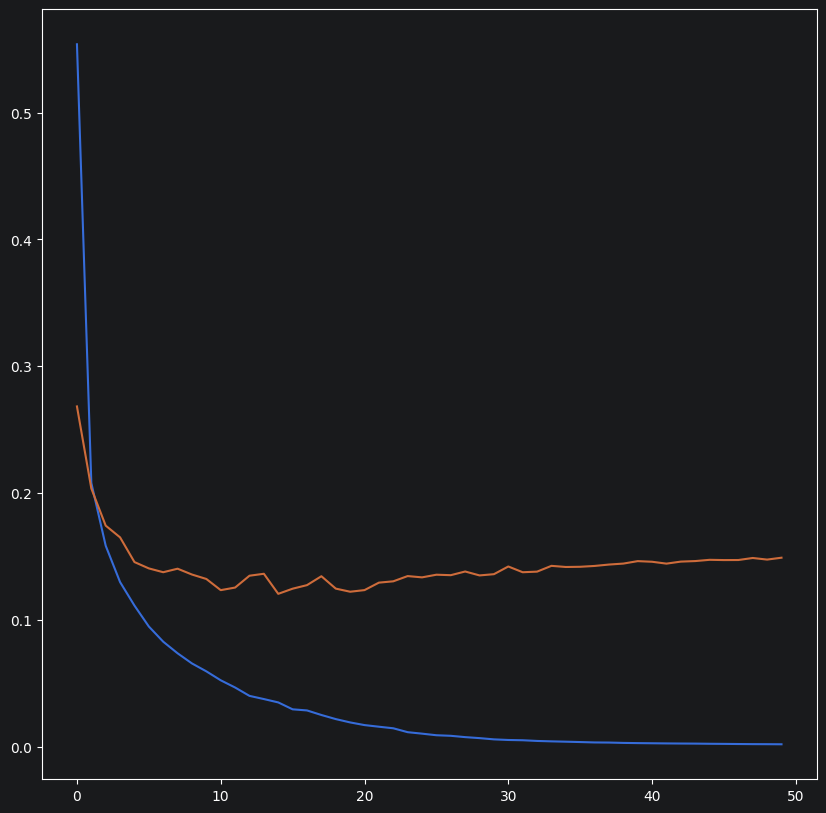

In [167]:
train_model(model_3,device,train_loader,optimizer_3,50,"model_3")

In [168]:
def evaluate_model(model, data_loader, device):
    model.eval()
    correct = 0
    total = len(data_loader.dataset)

    with torch.no_grad():
        for x_batch, y_batch in data_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            output = model(x_batch)
            preds = torch.argmax(output, dim=1)
            correct += (preds == y_batch).sum().item()

    accuracy = (correct / total) * 100
    return accuracy

# استفاده برای تست هر سه مدل
for idx, m in enumerate(list_model, start=1):
    test_acc = evaluate_model(m, test_loader, device)
    print(f"Model {idx} Test Accuracy: {test_acc:.2f}%")

Model 1 Test Accuracy: 97.61%
Model 2 Test Accuracy: 98.19%
Model 3 Test Accuracy: 97.19%
